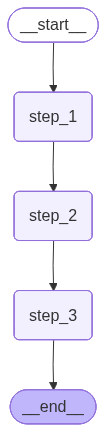

In [4]:
from langchain_core.messages import AnyMessage, AIMessage, HumanMessage
from langchain_core.runnables import configurable
from langchain_core.runnables.graph_mermaid import draw_mermaid, draw_mermaid_png
from pydantic_graph.beta import graph_builder
from transformers.models.ctrl import configuration_ctrl
from typing_extensions import TypedDict
from IPython.display import Image,display
from langgraph.graph import START,END,StateGraph

class State(TypedDict):
    value_1:str
    value_2:str
def step_1(state:State):
    return {"value_1":"a"}
def step_2(state:State):
    current_value_1 = state["value_1"]
    return {"value_1":f"{current_value_1}+b"}
def step_3(state:State):
    return {"value_2":"10"}

graph_builder = StateGraph(State)
graph_builder.add_node(step_1)
graph_builder.add_node(step_2)
graph_builder.add_node(step_3)
graph_builder.add_edge(START,"step_1")
graph_builder.add_edge("step_1","step_2")
graph_builder.add_edge("step_2","step_3")
graph_builder.add_edge("step_3",END)
graph = graph_builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [8]:
graph.invoke({"value1":"avq"})

{'value_1': 'a+b', 'value_2': '10'}

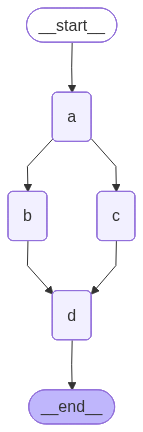

In [9]:
#分支控制
import operator
import operator
from typing import Any, Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
class State(TypedDict):
    #Annoteted 一个累加器# 节点 A 返回 {"aggregate": [1]}
    # 节点 B 返回 {"aggregate": [2]}
    # 最终 State: {"aggregate": [1, 2]}  <-- 数据被接上去了！
    aggregate:Annotated[list,operator.add]
def a(state:State):
    print(f"添加A到{state['aggregate']}")
    return {"aggregate":["A"]}
def b(state:State):
    print(f"添加B到{state['aggregate']}")
    return {"aggregate":["B"]}
def c(state:State):
    print(f"添加C到{state['aggregate']}")
    return {"aggregate":["C"]}
def d(state:State):
    print(f"添加D到{state['aggregate']}")
    return {"aggregate":["D"]}

builder = StateGraph(State)
builder.add_node(a)
builder.add_node(b)
builder.add_node(c)
builder.add_node(d)

builder.add_edge(START, "a")
builder.add_edge("a", "b")
builder.add_edge("a", "c")
builder.add_edge("b", "d")
builder.add_edge("c", "d")
builder.add_edge("d", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [11]:
graph.invoke({"aggregate":[]},{"configurable":{"thread_id":"foo"}})

添加A到[]
添加B到['A']
添加C到['A']
添加D到['A', 'B', 'C']


{'aggregate': ['A', 'B', 'C', 'D']}

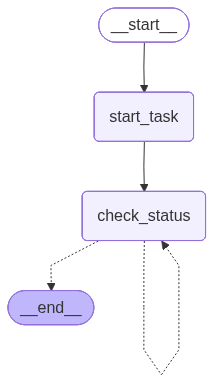


--- 开始执行图逻辑 ---

[节点 A] 发起 Web3 交易任务...
检查中... 当前计数: 1
决策 >> 任务未完成，准备跳回 [节点 B] 重试...


GraphRecursionError: Recursion limit of 2 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/GRAPH_RECURSION_LIMIT

In [19]:
import operator
from typing import Annotated, TypedDict, Literal
from IPython.display import Image, display

# 确保安装了 langgraph
from langgraph.graph import StateGraph, START, END

# --- 1. 定义状态 (State) ---
class State(TypedDict):
    status: str
    # 使用 operator.add 实现自动累加，这是做循环计数或记录日志的神器
    retry_count: Annotated[int, operator.add]

# --- 2. 定义节点 (Nodes) ---
def start_task(state: State):
    print("\n[节点 A] 发起 Web3 交易任务...")
    # 初始 status 为 pending，retry_count 增加 1
    return {"status": "pending", "retry_count": 1}

def check_status(state: State):
    current_retry = state["retry_count"]
    print(f"检查中... 当前计数: {current_retry}")

    if current_retry < 3:
        # ✅ 正确：返回 1，让 Annotated[int, operator.add] 把它加上去
        return {"status": "pending", "retry_count": 1}
    else:
        return {"status": "success"}

# --- 3. 定义路由逻辑 (Conditional Router) ---
def decide_next_node(state: State) -> Literal["check_status", END]:
    if state["status"] == "success":
        print("决策 >> 任务成功！流程结束。")
        return END
    else:
        print("决策 >> 任务未完成，准备跳回 [节点 B] 重试...")
        return "check_status"

# --- 4. 构建图结构 (Graph Construction) ---
builder = StateGraph(State)

# 添加节点
builder.add_node("start_task", start_task)
builder.add_node("check_status", check_status)

# 设置逻辑连线
builder.add_edge(START, "start_task")
builder.add_edge("start_task", "check_status")

# 设置条件分支：从 check_status 出发，根据 decide_next_node 的返回值决定去向
builder.add_conditional_edges(
    "check_status",
    decide_next_node
)

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

# 1. 输入 Key 必须与 State 定义一致
# 2. recursion_limit 必须大于循环步数（这里 3 次循环至少需要 5 步执行）
inputs = {"status": "init", "retry_count": 0}
config = {"recursion_limit": 10}

print("\n--- 开始执行图逻辑 ---")
final_state = graph.invoke(inputs, config)
print("\n--- 执行完成 ---")
print(f"最终状态: {final_state}")

In [ ]:
#使用递归防止异常情况
